In [2]:
import pandas as pd
import numpy as np
import scipy
import sklearn
from sklearn.cross_decomposition import CCA
import skimage as ski
from skimage import measure

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
final_df = pd.read_csv('/nethome/krangan7/hallou/final_data_morph_gene.csv', index_col=0)

In [5]:
final_df

,expr_PC1,expr_PC2,expr_PC3,expr_PC4,expr_PC5,expr_PC6,expr_PC7,expr_PC8,expr_PC9,expr_PC10,...,morph_major_axis_length,morph_minor_axis_length,morph_circularity,morph_aspect_ratio,tm_spatial_block,tm_celltype,tm_boundary_annotation,tm_cell_id,dataset_id,mask_label.1
mask_label,,,,,,,,,,,,,,,,,,,,,
ds1_12,4.198162,3.502761,0.871960,3.343137,-2.562934,-2.169376,1.203869,-0.373027,-1.107529,-2.176210,...,147.414671,103.257241,0.685386,1.427645,2,Neural crest,Neural Crest,cell_0,ds1,12
ds1_13,6.078893,1.919130,0.409814,5.151943,-0.516347,-2.022025,3.677651,-0.455193,0.820077,0.478986,...,180.742619,95.404193,0.532332,1.894493,2,Cranial mesoderm,Neural Crest,cell_1,ds1,13
ds1_16,2.515633,1.957031,0.906783,1.703914,0.134468,-6.307563,-1.675047,-2.213225,0.026411,-5.251489,...,153.419252,122.853057,0.574628,1.248803,2,Surface ectoderm,Neural Crest,cell_2,ds1,16
ds1_29,7.977310,0.067676,-1.839576,4.113106,2.787754,-2.609364,1.367209,-3.047355,1.540241,-1.160425,...,143.580738,107.085873,0.648999,1.340800,2,Endothelium,Neural Crest,cell_3,ds1,29
ds1_30,10.102632,-0.742317,-2.210175,3.846523,5.267537,-0.369564,-0.004903,-1.660684,-0.544094,-2.825981,...,148.646109,98.463037,0.571080,1.509664,2,Endothelium,Neural Crest,cell_4,ds1,30
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ds3_1408,-4.312479,-5.766491,0.727461,-0.822614,0.302080,1.697981,3.254060,2.330244,3.199616,0.821145,...,74.387011,57.514269,0.656333,1.293366,1,Forebrain/Midbrain/Hindbrain,Other,cell_911,ds3,1408
ds3_1409,-4.634804,-2.087311,2.547177,0.529365,1.566169,1.589451,2.229607,-0.098193,0.660508,-0.229611,...,53.387535,47.755549,0.712074,1.117934,1,Forebrain/Midbrain/Hindbrain,Other,cell_912,ds3,1409
ds3_1410,1.582523,-5.025133,0.224570,2.833497,1.763142,0.723220,2.797369,2.658414,2.187899,1.678293,...,107.111373,51.915663,0.523711,2.063180,3,Forebrain/Midbrain/Hindbrain,Other,cell_913,ds3,1410


In [11]:
final_df_1 = final_df[final_df['dataset_id']=='ds1']
final_df_2 = final_df[final_df['dataset_id']=='ds2']
final_df_3 = final_df[final_df['dataset_id']=='ds3']


In [16]:
morph_cols = final_df.filter(like='morph_').columns

In [15]:

def get_null_df(df, morph_cols, strata_cols = ['tm_spatial_block', 'tm_celltype','tm_boundary_annotation'], seed =0):
    """
    Get a null dataframe by shuffling the morph columns within strata defined by strata_cols.
    """
    perm_values = np.random.default_rng(seed)
    null_df = df.copy()
    morph_vals = df[morph_cols].values
    perm = np.arange(len(df))

    for ix in df.groupby(list(strata_cols)).indices.values():
        perm[ix] = perm_values.permutation(ix)
    null_df[morph_cols] = morph_vals[perm]
    return null_df



In [17]:
null_final_df_1= get_null_df(final_df_1, morph_cols=morph_cols)
null_final_df_2= get_null_df(final_df_2, morph_cols=morph_cols)
null_final_df_3= get_null_df(final_df_3, morph_cols=morph_cols)

In [19]:
null_final_df_1

,expr_PC1,expr_PC2,expr_PC3,expr_PC4,expr_PC5,expr_PC6,expr_PC7,expr_PC8,expr_PC9,expr_PC10,...,morph_major_axis_length,morph_minor_axis_length,morph_circularity,morph_aspect_ratio,tm_spatial_block,tm_celltype,tm_boundary_annotation,tm_cell_id,dataset_id,mask_label.1
mask_label,,,,,,,,,,,,,,,,,,,,,
ds1_12,4.198162,3.502761,0.871960,3.343137,-2.562934,-2.169376,1.203869,-0.373027,-1.107529,-2.176210,...,133.327477,104.414463,0.714550,1.276906,2,Neural crest,Neural Crest,cell_0,ds1,12
ds1_13,6.078893,1.919130,0.409814,5.151943,-0.516347,-2.022025,3.677651,-0.455193,0.820077,0.478986,...,180.742619,95.404193,0.532332,1.894493,2,Cranial mesoderm,Neural Crest,cell_1,ds1,13
ds1_16,2.515633,1.957031,0.906783,1.703914,0.134468,-6.307563,-1.675047,-2.213225,0.026411,-5.251489,...,139.855190,81.916424,0.550381,1.707291,2,Surface ectoderm,Neural Crest,cell_2,ds1,16
ds1_29,7.977310,0.067676,-1.839576,4.113106,2.787754,-2.609364,1.367209,-3.047355,1.540241,-1.160425,...,162.119795,94.323689,0.634986,1.718760,2,Endothelium,Neural Crest,cell_3,ds1,29
ds1_30,10.102632,-0.742317,-2.210175,3.846523,5.267537,-0.369564,-0.004903,-1.660684,-0.544094,-2.825981,...,144.914297,82.867262,0.512777,1.748752,2,Endothelium,Neural Crest,cell_4,ds1,30
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ds1_1632,2.769079,3.996888,-0.796939,-2.646469,-0.646338,-0.379697,5.715013,-4.601780,4.676798,1.376755,...,97.004241,60.454825,0.469089,1.604574,1,Mixed mesenchymal mesoderm,Other,cell_1158,ds1,1632
ds1_1636,1.820422,5.073541,-2.364468,-3.224097,-2.311871,-1.365875,4.511561,-4.799050,4.175815,0.227362,...,182.051878,60.905955,0.461207,2.989065,1,Mixed mesenchymal mesoderm,Other,cell_1159,ds1,1636
ds1_1643,1.387264,6.513906,-1.208869,-4.012485,-0.495506,-3.162277,3.809147,-2.990545,1.057985,0.453199,...,118.064648,72.665427,0.645686,1.624771,1,Mixed mesenchymal mesoderm,Other,cell_1160,ds1,1643


In [20]:
exp_matrix1 = pd.read_csv('/nethome/krangan7/hallou/exp_matrix1.csv', index_col=0)
exp_matrix2 = pd.read_csv('/nethome/krangan7/hallou/exp_matrix2.csv', index_col=0)
exp_matrix3 = pd.read_csv('/nethome/krangan7/hallou/exp_matrix3.csv', index_col=0)

In [21]:
exp_matrix1

,Abcc4,Acp5,Acvr1,Acvr2a,Adora2b,Afp,Ahnak,Akr1c19,Alas2,Aldh1a2,...,Wnt2b,Wnt3,Wnt3a,Wnt5a,Wnt5b,Wnt8a,Xist,Zfp444,Zfp57,Zic3
mask_label,,,,,,,,,,,,,,,,,,,,,
12,0,2,0,1,0,0,2,1,0,0,...,3,0,1,1,0,0,1,1,2,3
13,0,0,0,1,0,1,8,1,2,1,...,2,0,0,0,0,0,4,4,3,4
16,0,0,0,0,0,0,5,1,0,0,...,0,0,0,0,0,1,7,1,0,2
29,1,1,0,1,0,0,2,0,0,0,...,5,1,0,0,0,0,3,1,3,2
30,0,1,0,1,0,0,2,2,1,0,...,0,2,0,0,1,1,2,2,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1632,0,1,1,0,0,0,2,0,1,0,...,0,0,0,5,1,0,2,1,1,0
1636,1,0,0,0,0,0,2,0,0,0,...,0,0,0,1,0,0,1,1,1,0
1643,0,0,0,1,0,0,1,0,0,0,...,0,0,1,2,0,0,0,0,0,0


In [23]:
exp_matrix1

,Abcc4,Acp5,Acvr1,Acvr2a,Adora2b,Afp,Ahnak,Akr1c19,Alas2,Aldh1a2,...,Wnt2b,Wnt3,Wnt3a,Wnt5a,Wnt5b,Wnt8a,Xist,Zfp444,Zfp57,Zic3
mask_label,,,,,,,,,,,,,,,,,,,,,
12,0,2,0,1,0,0,2,1,0,0,...,3,0,1,1,0,0,1,1,2,3
13,0,0,0,1,0,1,8,1,2,1,...,2,0,0,0,0,0,4,4,3,4
16,0,0,0,0,0,0,5,1,0,0,...,0,0,0,0,0,1,7,1,0,2
29,1,1,0,1,0,0,2,0,0,0,...,5,1,0,0,0,0,3,1,3,2
30,0,1,0,1,0,0,2,2,1,0,...,0,2,0,0,1,1,2,2,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1632,0,1,1,0,0,0,2,0,1,0,...,0,0,0,5,1,0,2,1,1,0
1636,1,0,0,0,0,0,2,0,0,0,...,0,0,0,1,0,0,1,1,1,0
1643,0,0,0,1,0,0,1,0,0,0,...,0,0,1,2,0,0,0,0,0,0


In [24]:
cells_1 = final_df_1.index
cells_1

Index(['ds1_12', 'ds1_13', 'ds1_16', 'ds1_29', 'ds1_30', 'ds1_32', 'ds1_36',
       'ds1_37', 'ds1_38', 'ds1_39',
       ...
       'ds1_1625', 'ds1_1626', 'ds1_1629', 'ds1_1630', 'ds1_1631', 'ds1_1632',
       'ds1_1636', 'ds1_1643', 'ds1_1651', 'ds1_1658'],
      dtype='str', name='mask_label', length=1039)

In [28]:
exp_matrix1.index = 'ds1_' + exp_matrix1.index.astype(str)


In [30]:
exp_matrix2.index = 'ds2_' + exp_matrix2.index.astype(str)
exp_matrix3.index = 'ds3_' + exp_matrix3.index.astype(str)


In [32]:
cells_1 = final_df_1.index

genes_counts_1 = exp_matrix1.loc[cells_1].add_prefix('gene')
total_counts_1 = genes_counts_1.sum(axis=1)
keep_1 = total_counts_1 >= 20                                  # drop cells with too few molecules
counts_1, total_counts_1 = genes_counts_1[keep_1], total_counts_1[keep_1]

cells_2 = final_df_2.index

genes_counts_2 = exp_matrix2.loc[cells_2].add_prefix('gene')
total_counts_2 = genes_counts_2.sum(axis=1)
keep_2 = total_counts_2 >= 20                                  # drop cells with too few molecules
counts_2, total_counts_2 = genes_counts_2[keep_2], total_counts_2[keep_2]

cells_3 = final_df_3.index

genes_counts_3 = exp_matrix3.loc[cells_3].add_prefix('gene')
total_counts_3 = genes_counts_3.sum(axis=1)
keep_3 = total_counts_3 >= 20                                  # drop cells with too few molecules
counts_3, total_counts_3 = genes_counts_3[keep_3], total_counts_3[keep_3]




In [35]:
cat1 = final_df_1[[ 'tm_celltype', 'tm_boundary_annotation']].astype(str)
groups1 = final_df_1['tm_spatial_block']
 
cat2 = final_df_2[[ 'tm_celltype', 'tm_boundary_annotation']].astype(str)
groups2 = final_df_2['tm_spatial_block']

cat3 = final_df_3[[ 'tm_celltype', 'tm_boundary_annotation']].astype(str)
groups3 = final_df_3['tm_spatial_block']


In [34]:
import cca_comparison as cca

In [37]:
cca_resid_exp_1 = cca.heldout_cca(final_df_1.filter(like='morph_'), final_df_1.filter(like='expr_'), cat1, total_counts_1, groups1, n_comp=3)
cca_resid_exp_2 = cca.heldout_cca(final_df_2.filter(like='morph_'), final_df_2.filter(like='expr_'), cat2, total_counts_2, groups2, n_comp=3)
cca_resid_exp_3 = cca.heldout_cca(final_df_3.filter(like='morph_'), final_df_3.filter(like='expr_'), cat3, total_counts_3, groups3, n_comp=3)

In [38]:
null_cca_resid_exp_1 = cca.heldout_cca(null_final_df_1.filter(like='morph_'), null_final_df_1.filter(like='expr_'), cat1, total_counts_1, groups1, n_comp=3)
null_cca_resid_exp_2 = cca.heldout_cca(null_final_df_2.filter(like='morph_'), null_final_df_2.filter(like='expr_'), cat2, total_counts_2, groups2, n_comp=3)
null_cca_resid_exp_3 = cca.heldout_cca(null_final_df_3.filter(like='morph_'), null_final_df_3.filter(like='expr_'), cat3, total_counts_3, groups3, n_comp=3)

In [45]:
def null_panel(ax, null_k, obs_k, title, fold_k=None):
    p = (1 + (null_k >= obs_k).sum()) / (1 + len(null_k))
    p95 = np.percentile(null_k, 95)
    mu = null_k.mean()

    ax.hist(null_k, bins=25, color='#c9c5b8', edgecolor='white', linewidth=0.5, label="Null CCA Values")
    ax.axvline(p95, color='#6f695c', ls='--', lw=1,label=f"Null 95th percentile = {p95:.2f}")
    ax.axvline(mu, color='#6f695c', lw=1.5, label=f"Null mean = {mu:.2f}")
    ax.axvline(obs_k, color='#c0392b', lw=2, label=f"Observed CCA {obs_k:.2f}, p = {p:.3f}")

    if fold_k is not None:
        ax.plot(fold_k, np.full(len(fold_k), ax.get_ylim()[1] * 0.04), 'o',
                color='#c0392b', alpha=0.6, ms=4, clip_on=False)

    ax.set_title(title, fontsize=10, loc='left')
    ax.set_xlabel('Held-out canonical correlation')
    ax.set_ylabel('Permutations')
    ax.legend(fontsize=7, loc='upper left', frameon=False)
    ax.text(0.97, 0.95, f'observed = {obs_k:.2f}\nnull 95th pct = {p95:.2f}\np = {p:.3f}',
            transform=ax.transAxes, ha='right', va='top', fontsize=8)

In [49]:
E_1 = final_df_1.filter(like='expr_')
E_2 = final_df_2.filter(like='expr_')
E_3 = final_df_3.filter(like='expr_')

In [54]:
null_1 = np.empty((200, 3))

for i in range(200):
    M_b = get_null_df(final_df_1, morph_cols, seed=i)[morph_cols]
    null_1[i] = cca.heldout_cca(M_b, E_1, cat1, total_counts_1, groups1, n_comp=3)[0]



In [55]:
null_2 = np.empty((200, 3))

for i in range(200):
    M_b = get_null_df(final_df_2, morph_cols, seed=i)[morph_cols]
    null_2[i] = cca.heldout_cca(M_b, E_2, cat2, total_counts_2, groups2, n_comp=3)[0]



In [56]:
null_3 = np.empty((200, 3))

for i in range(200):
    M_b = get_null_df(final_df_3, morph_cols, seed=i)[morph_cols]
    null_3[i] = cca.heldout_cca(M_b, E_3, cat3, total_counts_3, groups3, n_comp=3)[0]


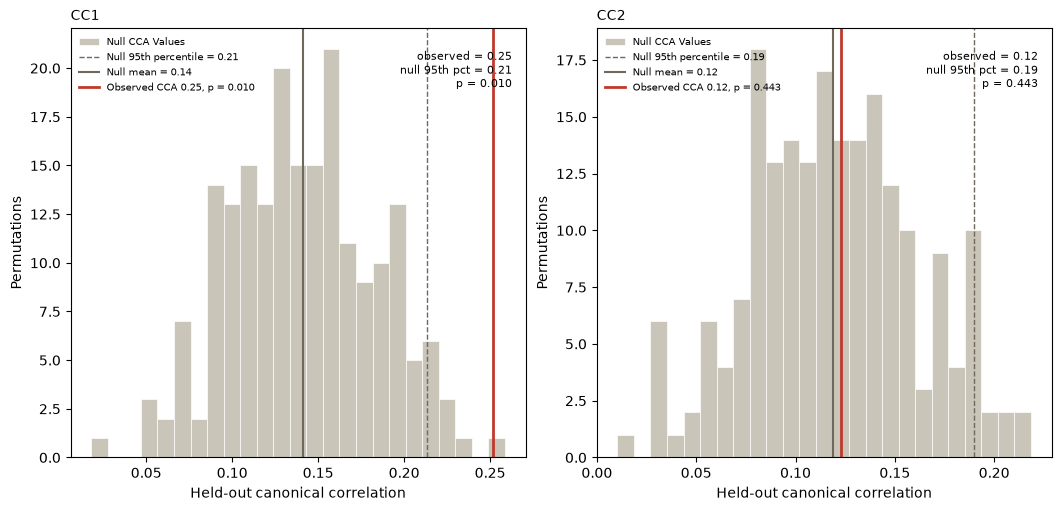

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(10.5,5), constrained_layout=True)
null_panel(axes[0], null_1[:, 0], cca_resid_exp_1[0][0], 'CC1')
null_panel(axes[1], null_1[:, 1], cca_resid_exp_1[1][1], 'CC2')


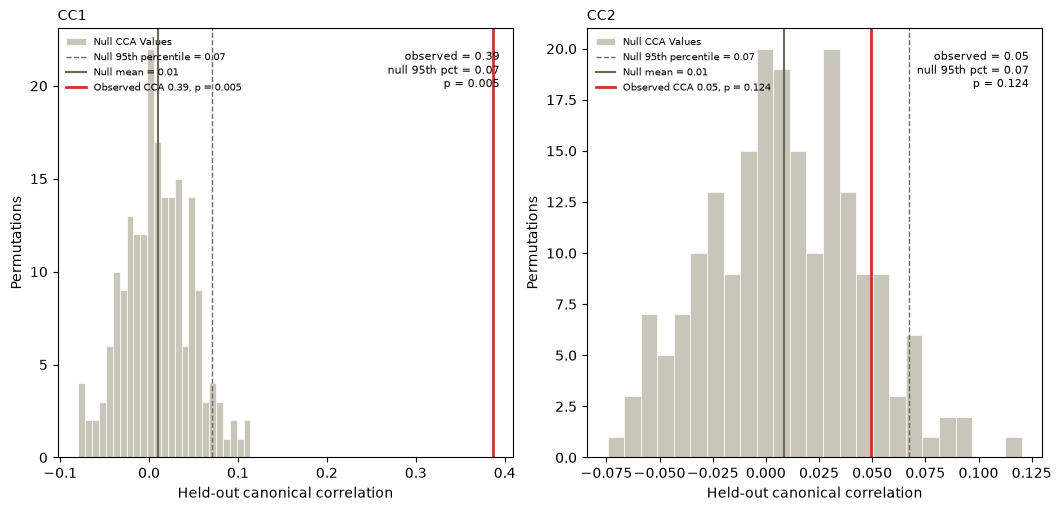

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(10.5,5), constrained_layout=True)
null_panel(axes[0], null_2[:, 0], cca_resid_exp_2[0][0], 'CC1')
null_panel(axes[1], null_2[:, 1], cca_resid_exp_2[1][1], 'CC2')

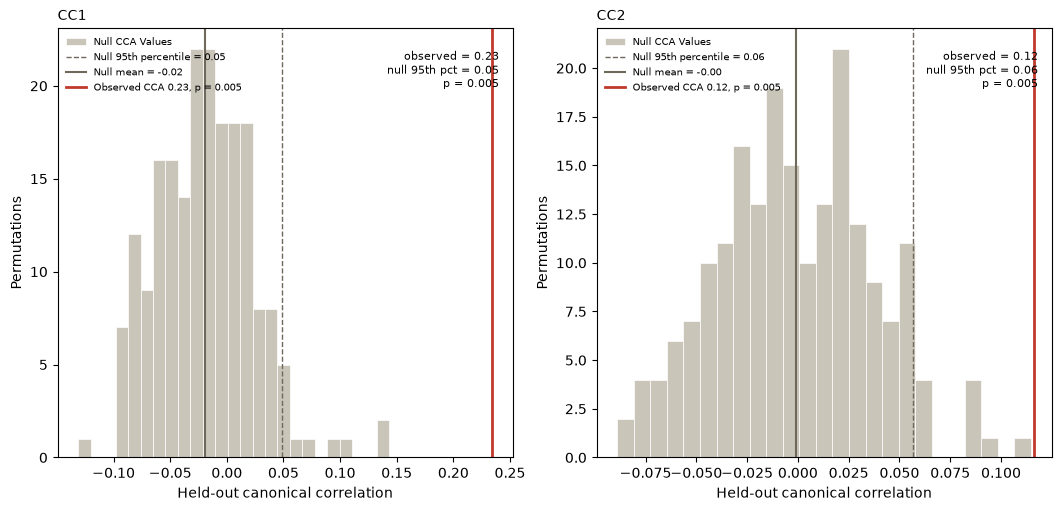

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(10.5,5), constrained_layout=True)
null_panel(axes[0], null_3[:, 0], cca_resid_exp_3[0][0], 'CC1')
null_panel(axes[1], null_3[:, 1], cca_resid_exp_3[1][1], 'CC2')